# Seeing a wind vector through two radar views

## 1. A volumetric inverse problem

Weather radar measures scatterer velocity along its beam rather than all three air-velocity components. Two separated real radars over Hurricane Florence provide complementary views of convection. We recover eastward, northward and upward wind volumes on9×21×21voxels. This is a conditional variational reconstruction, not independently measured physical wind truth. The method reference was computed by the original authors' unmodified JAX backend on exactly these observations.

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np,scipy
import matplotlib,matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src.physics_model import objective_gradient,forward,divergence
from src import visualization as viz
print('ACTUAL_KERNEL_ENVIRONMENT',json.dumps({'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}))
d=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:author=np.stack([f[k][0] for k in ['reconstruction','northward','vertical']])
sources={}
def show(name,result):
    fig,nums=result;sources.update({name+'_'+k:v for k,v in nums.items()});plt.show()
print({k:v.shape for k,v in d.items()},'valid radial observations',d['validity'].sum())

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "scipy": "1.17.1", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}
{'radial_velocity': (2, 9, 21, 21), 'reflectivity': (2, 9, 21, 21), 'azimuth': (2, 9, 21, 21), 'elevation': (2, 9, 21, 21), 'validity': (2, 9, 21, 21), 'x': (21,), 'y': (21,), 'z': (9,)} valid radial observations 6576.0


## 2. Actual radar data and geometry

The measurements are author-supplied NOAA NEXRAD volumes around06:24UTC on14September2018. Source gridding, radar calibration and velocity dealiasing are retained; we perform no new target-dependent preprocessing. A fixed physical subvolume was chosen using valid observations and original beam-crossing geometry. Historical reconstructed u/v/wfields inside the source files were explicitly removed before the oracle run and never enter the cleaned input. Missing samples carry0placeholders and zero radial weight. Angles are original known beam geometry; coordinates are metres east,north,up. Scan duration and fall-speed errors limit the frozen-time model.

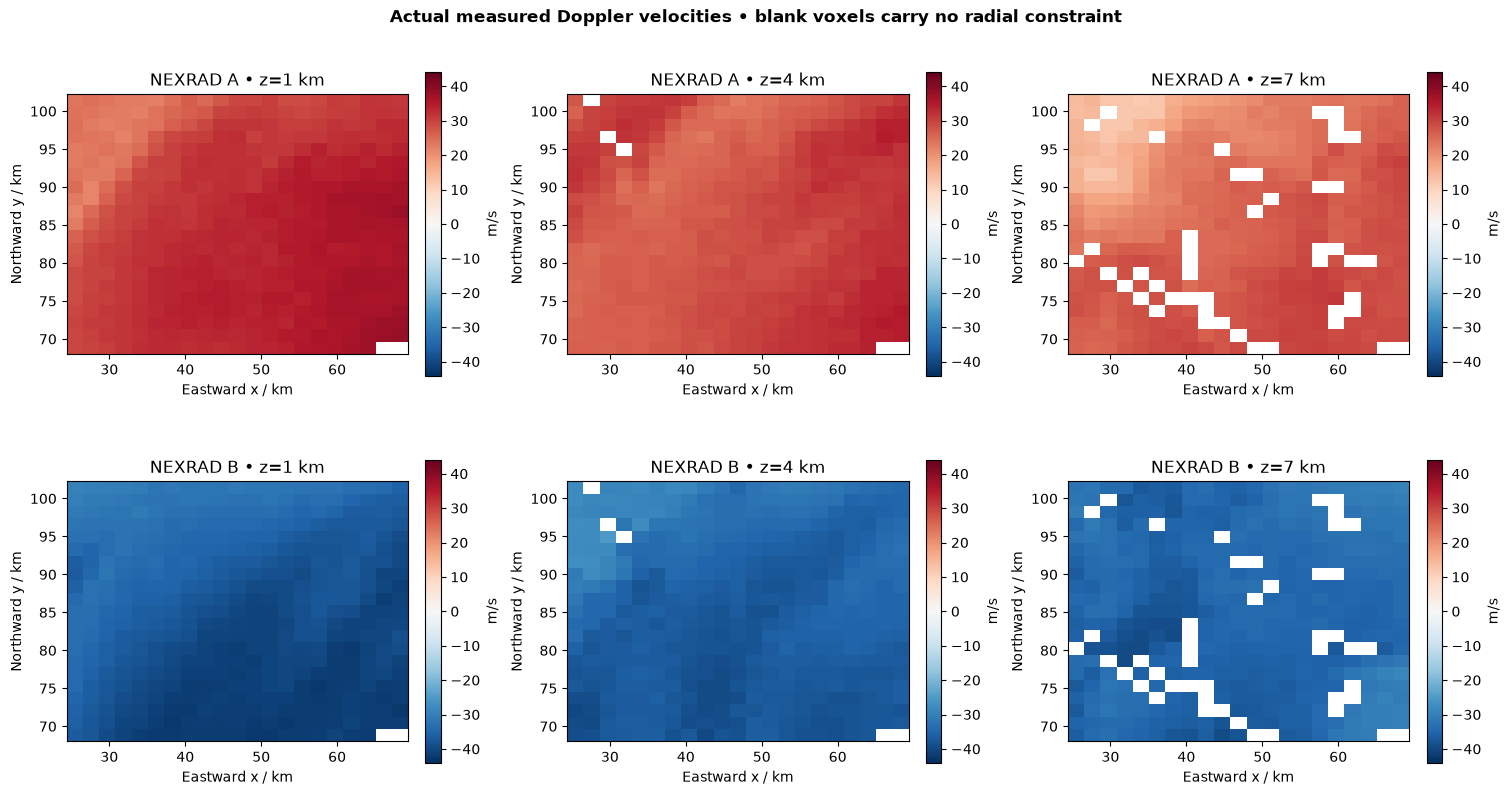

In [2]:
show('acquisition',viz.acquisition(d))

## 3. Physics and explicit local variational method

For radar r, the radial model is

$$d_r=\cos\epsilon_r\sin\alpha_r\,u+\cos\epsilon_r\cos\alpha_r\,v+\sin\epsilon_r(w-|v_{t,r}|)+e_r.$$

The terminal fall speed follows the original piecewise reflectivity/density law, with freezing level5000m. Azimuth is clockwise from north, elevation above horizontal. Specific cost terms are

$$J=\frac{\sum m_r(v_r-d_r)^2}{\sigma_V^2}+\frac{256}{2}\sum\left(D_xu+D_yv+D_zw+w\frac{D_z\rho}{\rho}\right)^2+10^{-4}\sum(u^2+v^2).$$

Here m is known binary coverage, sigmaV the observed valid radial RMS, rho=exp(−z/10000m)the assumed density, and D the one-sided-boundary/centered-interior first difference. The weak zero-horizontal-wind prior is an openly stated regularizer, **not** measured forecast calibration. The original model term excludes w, which remains indirectly constrained. w=0on the lowest and highest analysis planes; those are analysis-boundary approximations. No smoothing, vorticity, sounding or terrain term is substituted.

The original NumPy continuity gradient fails an exact discrete-adjoint check at boundaries and omits a density derivative term. We select the original JAX autodiff backend, rather than copy that discrepancy. Locally the task-specific projection, terminal speed, density, differences and exact adjoints are explicit NumPy mathematics. A general SciPy L-BFGS-Boptimizer reaches the same converged objective. The original JAXopt and local SciPy line searches differ; comparison therefore concerns converged physical optima, not identical intermediate iterations.

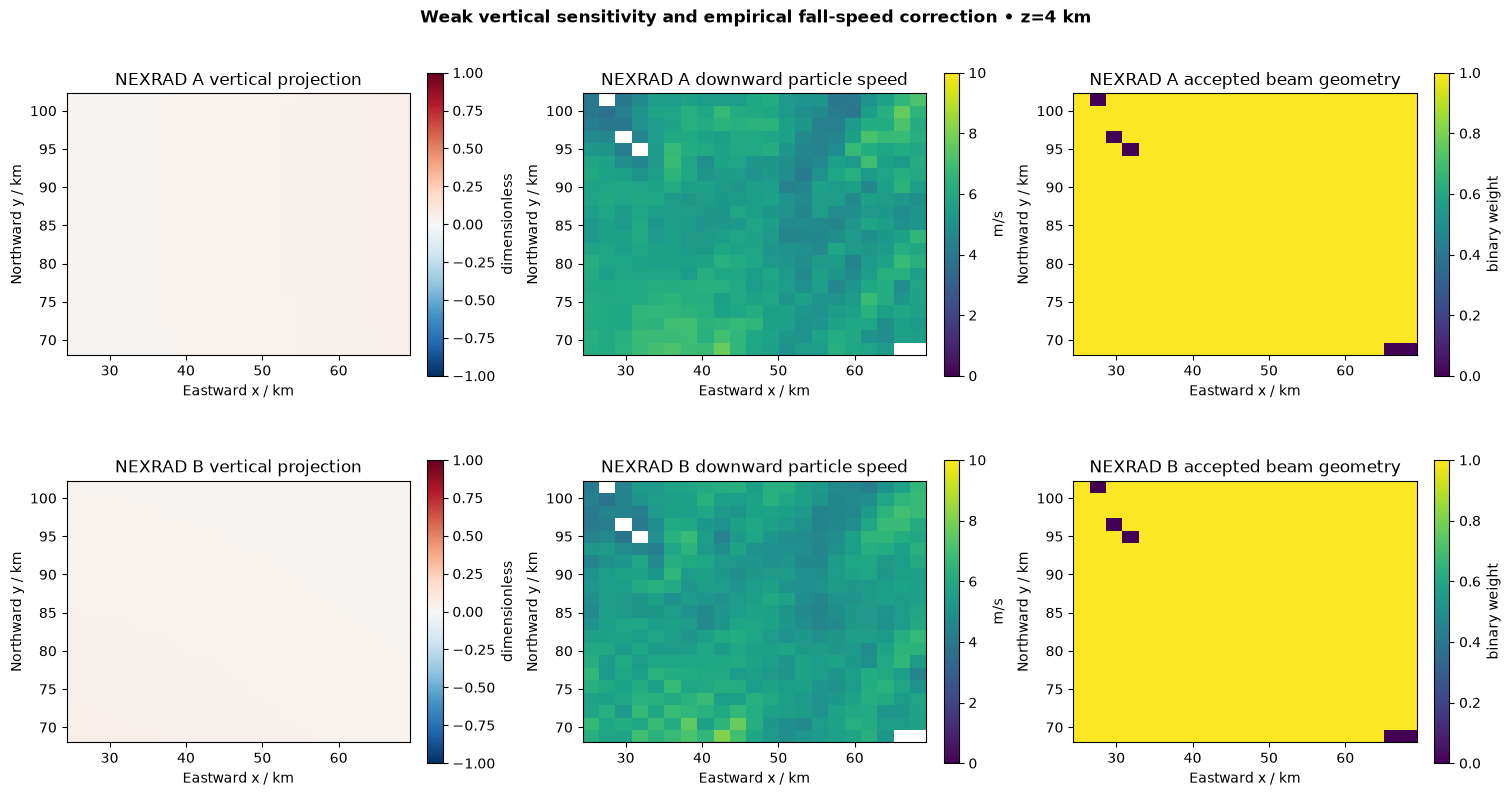

Fresh full-volume seconds 0.17707299999892712 {'objective': 448.8818667363543, 'iterations': 113, 'projected_gradient_max': 1.8318539033216306e-09}


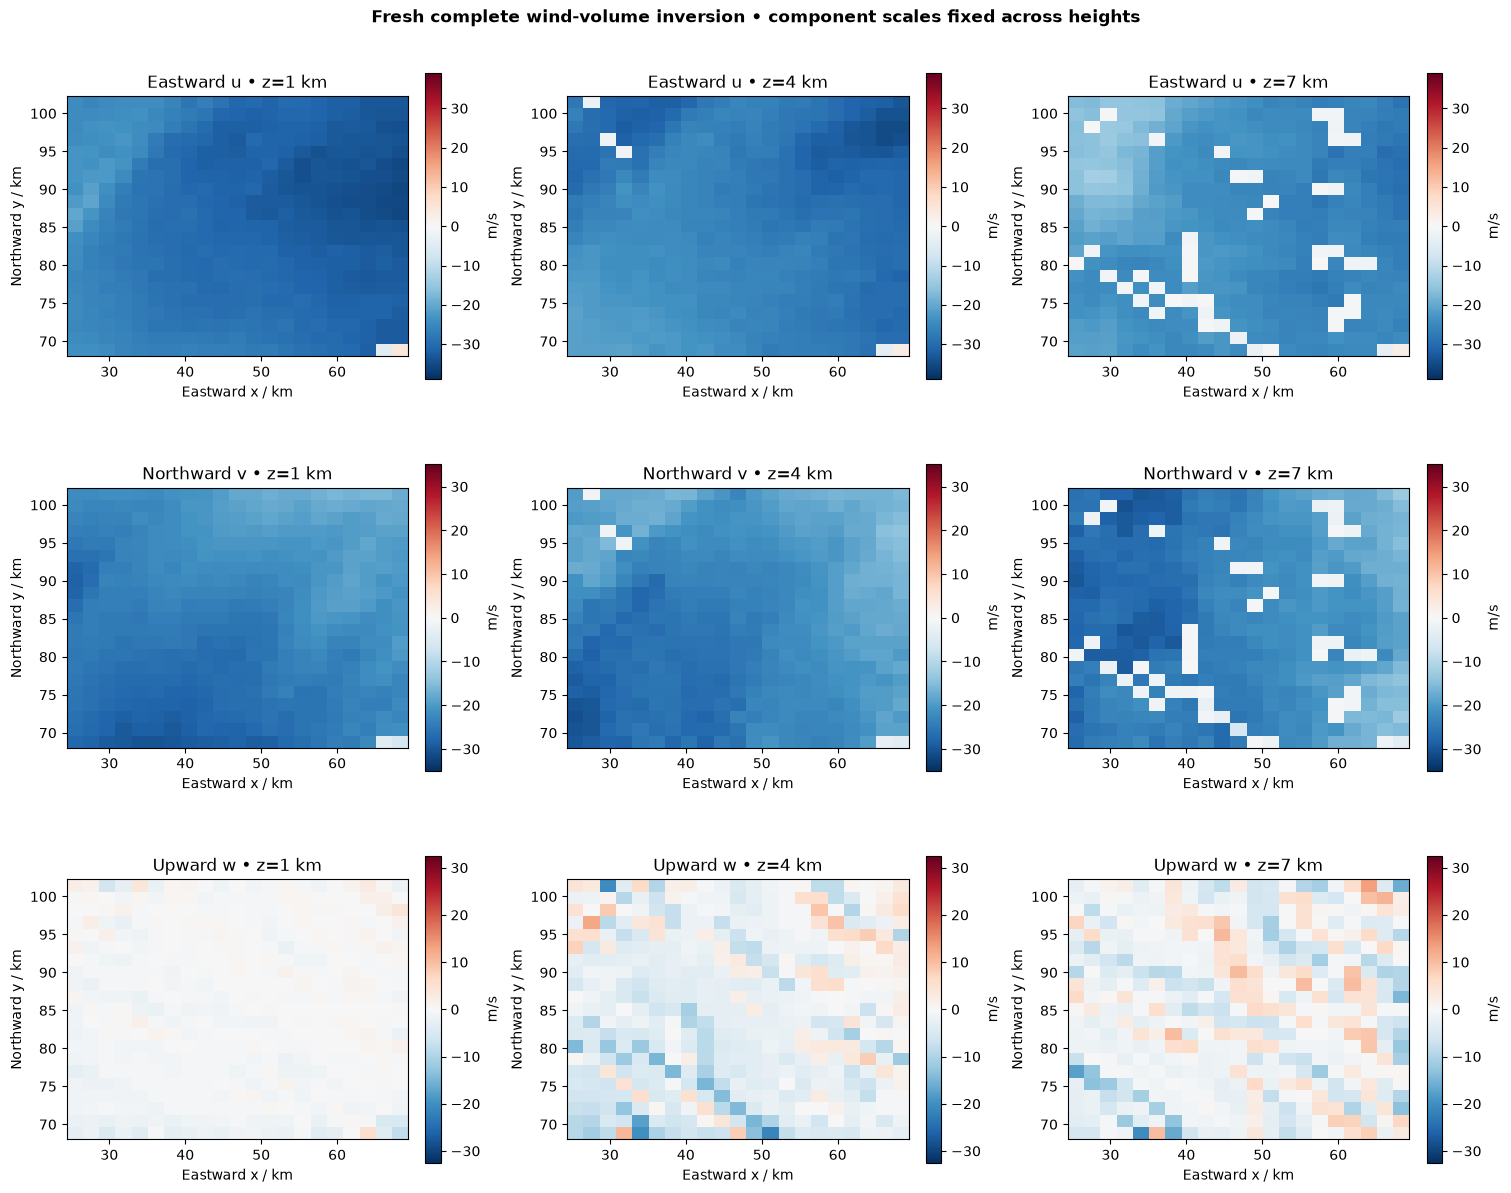

In [3]:
show('physics',viz.physics(d))
start=time.perf_counter();winds,pred,state=reconstruct(d);runtime=time.perf_counter()-start
print('Fresh full-volume seconds',runtime,state)
show('volume',viz.volume(d,winds))

## 4. Independent reproduction and observation evidence

Original JAX source runs converged with projected gradient below1e-8and were independently repeated. Fresh wind fields are computed above. Each component is scored at absolute m/sscale against that independent method reference; no physical truth is available. The full volumes are evaluated, even where observations are weak. Residual improvements relative to zero air wind (including the same hydrometeor correction) provide evidence beyond method agreement. The anelastic divergence and boundary profile expose remaining physical compromises.

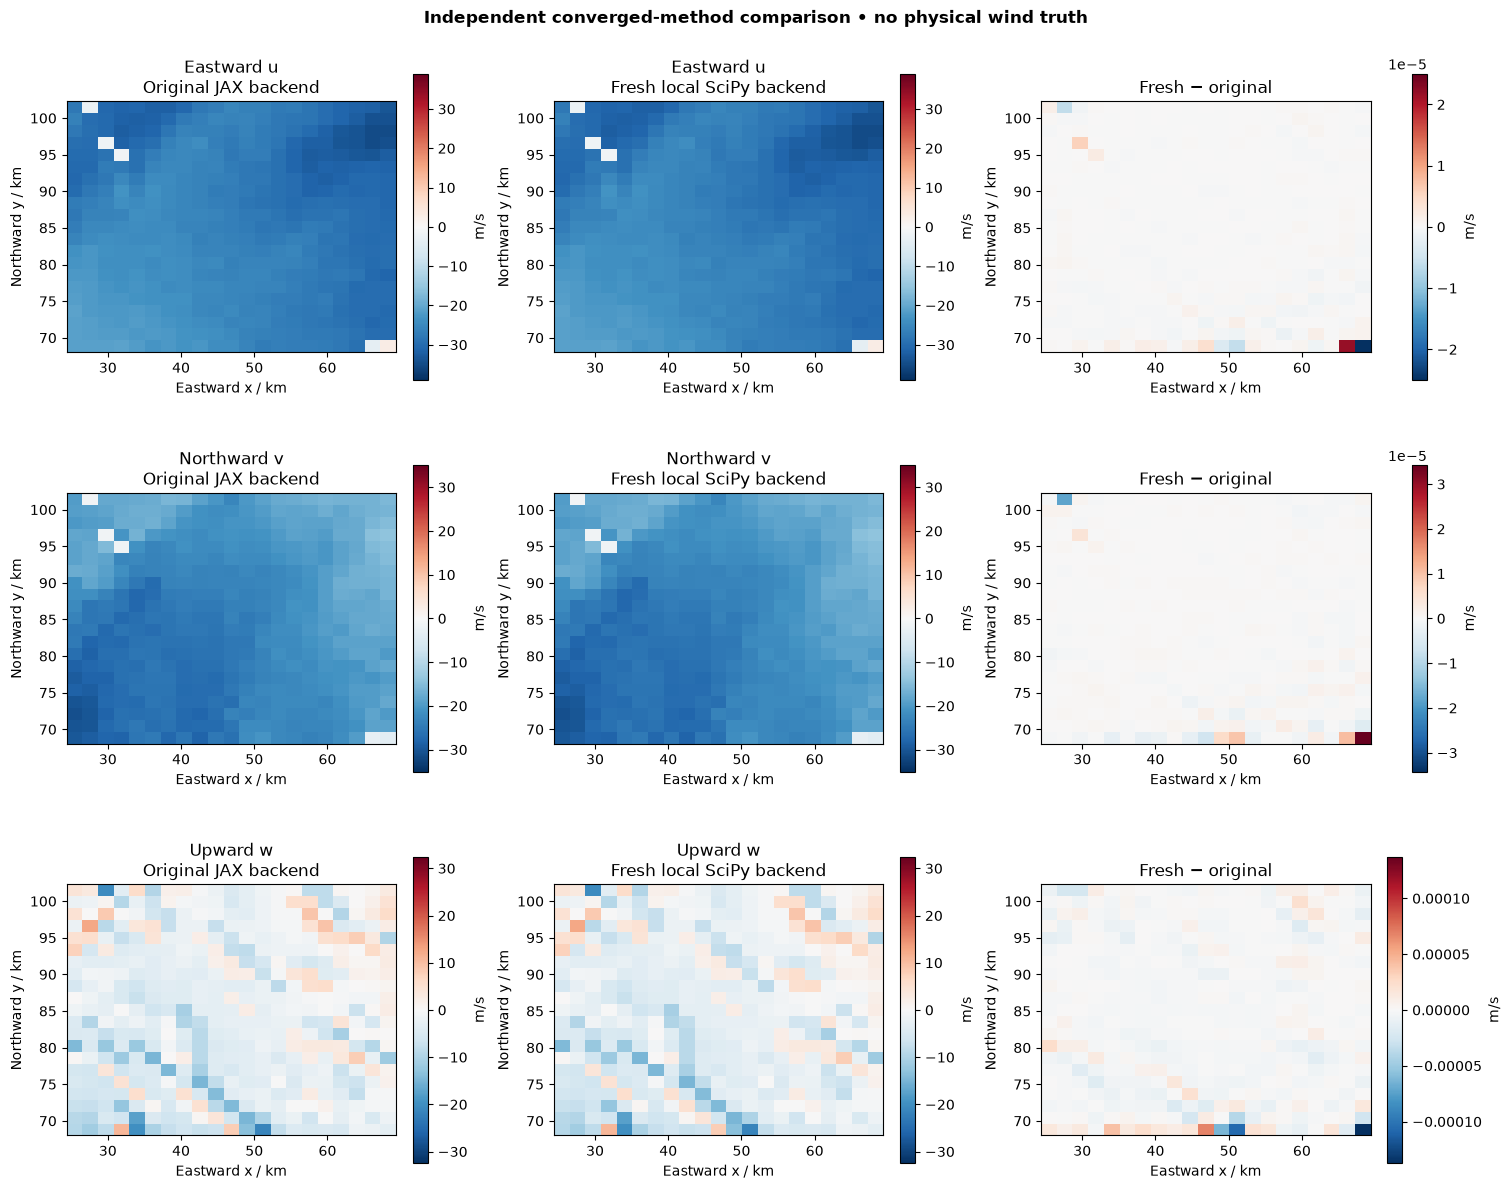

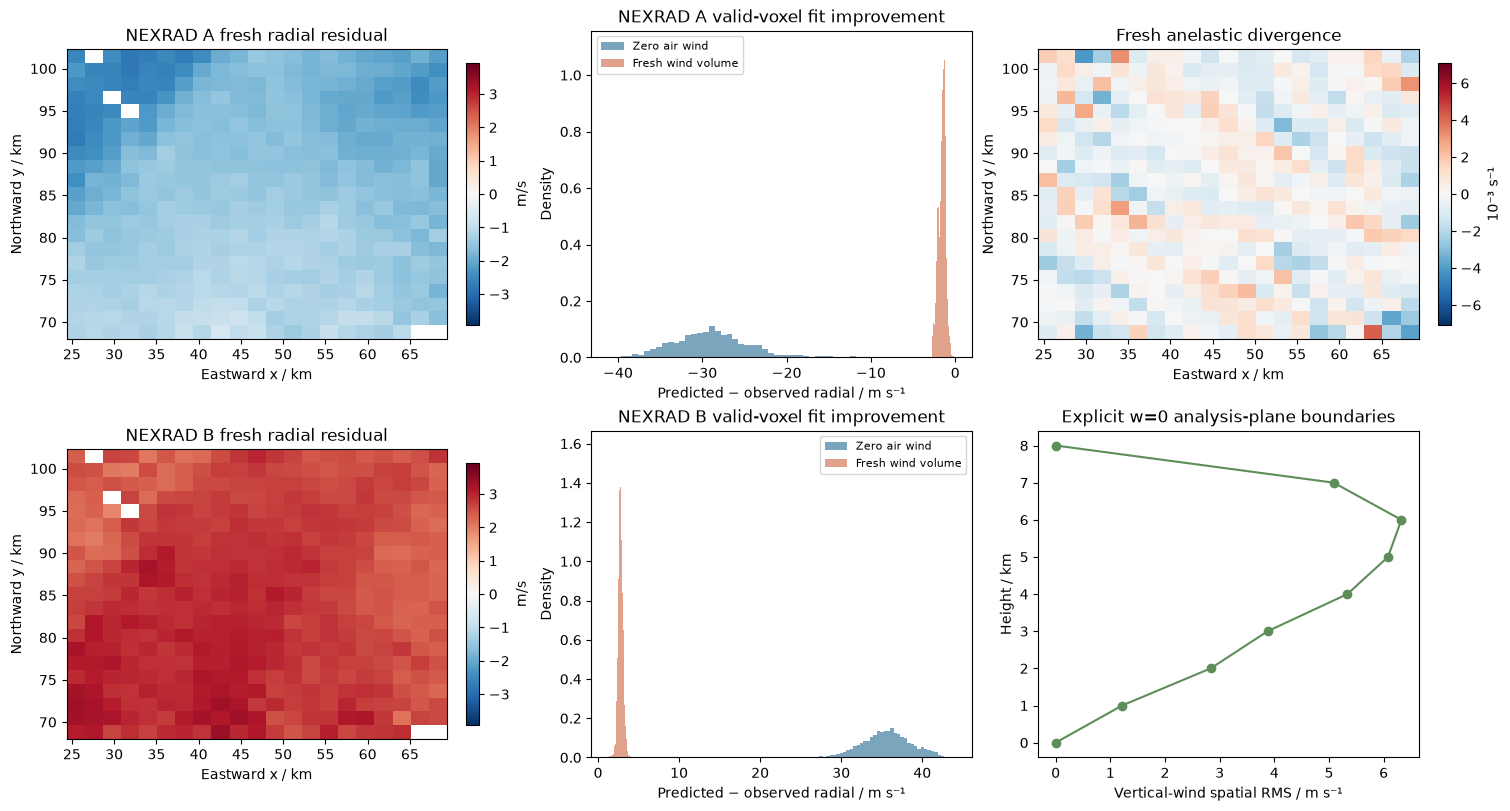

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999981,
    "reconstruction_nrmse": 3.747437651693141e-08,
    "northward_ncc": 0.9999999999999954,
    "northward_nrmse": 5.336375880012051e-08,
    "vertical_ncc": 0.9999999999977758,
    "vertical_nrmse": 1.6657585448329706e-07
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 5e-05
    },
    "northward_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "northward_nrmse": {
      "comparison": "<=",
      "boundary": 5e-05
    },
    "vertical_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "vertical_nrmse": {
      "comparison": "<=",
      "boundary": 5e-05
    }
  },
  "errors": []
}


In [4]:
show('comparison',viz.comparison(d,winds,author))
show('residuals',viz.residuals(d,winds,pred))
from importlib.util import spec_from_file_location,module_from_spec
s=spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=module_from_spec(s);s.loader.exec_module(judge)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=winds[0][None],northward=winds[1][None],vertical=winds[2][None]);report,code=judge.evaluate(root/'output/reconstruction.npz');assert code==0
print(json.dumps(report,indent=2))

## 5. Actual sensitivity experiments

Five complete reconstructions vary the horizontal zero-mean prior coefficient, while three more vary continuity. The data are identical in every run. We display the vertical-field response, valid radial RMS and whole-volume changes in each component. This is particularly relevant because the radar vertical projection is weaker and the source model term intentionally supplies no direct vertical prior. These curves are computed sensitivity, not posterior uncertainty or physical accuracy bounds.

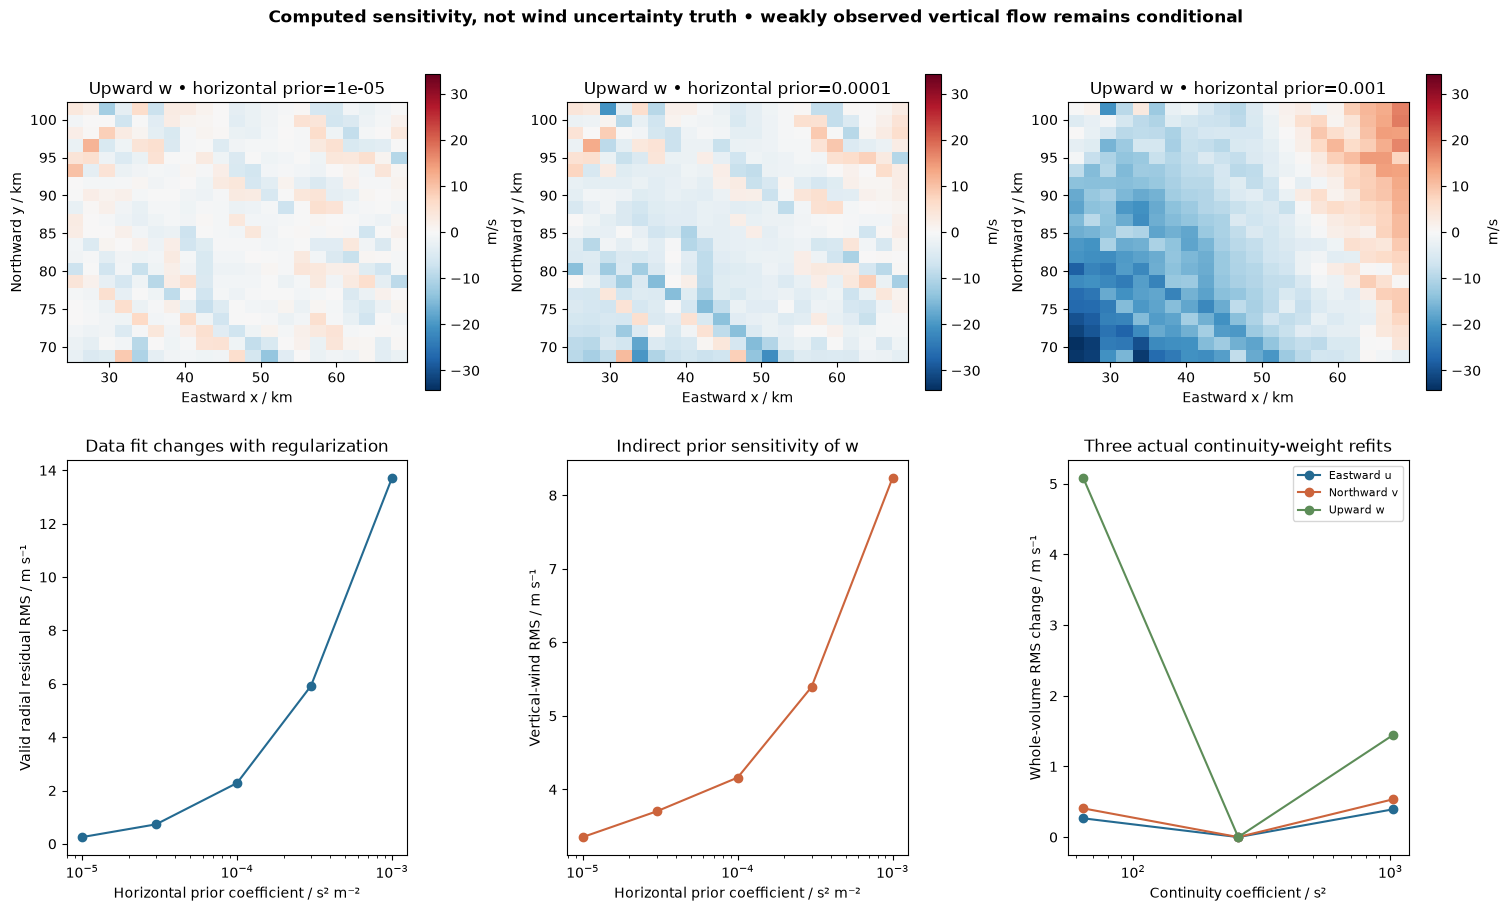

In [5]:
show('sensitivity',viz.sensitivity(d,winds))

## 6. Interpretation and limits

The explicit local inverse reproduces the independently converged original full variational wind solution and improves the fit to real radar projections. Its vertical structure remains conditional on geometry, terminal-speed law, continuity, finite scan duration and the horizontal prior. Large updraft or downdraft values should not be interpreted as independent verification of storm dynamics. Both component agreement and physical residual evidence are reported; neither replaces validation against actual wind measurements, which are unavailable here. Every displayed fresh alternative was computed during this execution.

In [6]:
print('Active complete-volume inversion and sensitivity studies finished; plotted numeric arrays',len(sources))

Active complete-volume inversion and sensitivity studies finished; plotted numeric arrays 18
